# Lab 2  — Task 1: Music Genre Classification with CNNs

Notebook dedicado exclusivamente a la **Task 1**: entrenar una CNN desde cero y comparar configuraciones de arquitectura e hiperparámetros. La **Task 2 (VGG16)** está en el notebook independiente `Lab2_Task2_VGG16_Music_Genre.ipynb`.

**Criterio de evaluación:** se reserva un 20 % para test antes de optimizar. El 80 % restante se divide en entrenamiento y validación. Las configuraciones se comparan usando únicamente validation accuracy; el test se evalúa una sola vez con la configuración elegida.

Los experimentos cambian un factor cada vez respecto a BASE0, excepto los experimentos de profundidad, que cambian la secuencia de filtros. La configuración de mayor resolución se ejecuta al final porque es la más costosa.

## 1. Imports y configuración

TensorFlow/Keras implementa la CNN. Si faltan librerías, descomenta y ejecuta la instalación. Las semillas ayudan a que la partición y los experimentos sean más reproducibles.

In [16]:
# %pip install tensorflow scikit-learn matplotlib
import os
import random
import gc
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import pandas as pd
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


## 2. Cargar las imágenes y separar los datos

Cada subcarpeta de images_original representa un género musical. La división inicial reserva el 20 % para test. Del 80 % restante se extrae un conjunto de validación; por tanto, aproximadamente el 64 % de todos los datos se usa para entrenar, el 16 % para validar y el 20 % para test.

In [17]:
# Ejemplo en Colab: '/content/drive/MyDrive/GTZAN/images_original'
DATA_DIR = 'Data/images_original'  # Ajusta la ruta si los datos están en otro lugar.
BATCH_SIZE = 32
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 4

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"No encuentro {DATA_DIR}. Cambia DATA_DIR para apuntar a images_original."
    )

class_names = sorted(
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
)
extensions = ('.png', '.jpg', '.jpeg', '.bmp')
paths, labels = [], []

for label, genre in enumerate(class_names):
    folder = os.path.join(DATA_DIR, genre)
    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith(extensions):
            paths.append(os.path.join(folder, filename))
            labels.append(label)

paths = np.asarray(paths)
labels = np.asarray(labels)

if len(paths) == 0:
    raise ValueError("No se han encontrado imágenes. Comprueba la estructura de carpetas.")

print("Géneros:", class_names)
print("Total de imágenes:", len(paths))

# Test queda separado antes de comenzar cualquier experimento.
dev_paths, test_paths, dev_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
# La validación procede solo del 80 % de desarrollo.
train_paths, val_paths, train_labels, val_labels = train_test_split(
    dev_paths, dev_labels, test_size=0.20, random_state=SEED, stratify=dev_labels
)

print(f"Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}")
print("No se usa test para comparar configuraciones.")

Géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de imágenes: 999
Train: 639 | Validation: 160 | Test: 200
No se usa test para comparar configuraciones.


## 3. Preparar datasets para distintas resoluciones

Cada configuración puede usar un tamaño de imagen distinto. Por eso las imágenes se redimensionan al construir los datasets de cada experimento. Solo se baraja el entrenamiento; validación y test mantienen el orden de las etiquetas.

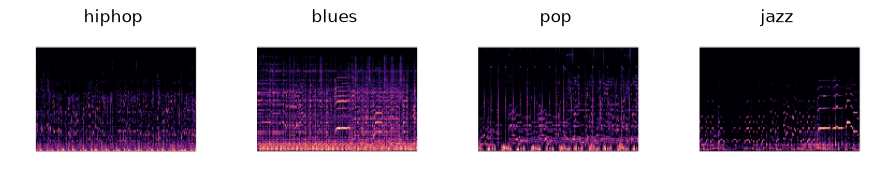

In [18]:
def load_image(path, label, size):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, size)
    return image, label


def make_dataset(file_paths, file_labels, size, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(
            buffer_size=len(file_paths), seed=SEED, reshuffle_each_iteration=True
        )
    ds = ds.map(
        lambda path, label: load_image(path, label, size),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Mostrar algunos ejemplos para comprobar que se cargan las imágenes correctamente.
preview_ds = make_dataset(train_paths, train_labels, size=(128, 192), training=True)
for images, labels_batch in preview_ds.take(1):
    plt.figure(figsize=(9, 3))
    for i in range(min(4, len(images))):
        plt.subplot(1, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels_batch[i])])
        plt.axis("off")
    plt.tight_layout()
    plt.show()
del preview_ds

## 4. Definir la CNN y los experimentos

BASE0 se ha cambiado para no copiar literalmente la configuración de referencia. Se parte de filtros (24, 48, 96), kernel 3×3, dropout 0.25, augmentation activado, learning rate 0.0005 y resolución 128×192.

Los experimentos cubren:
- **Profundidad y capacidad:** secuencias de 2 a 5 bloques convolucionales y distintos números de filtros.
- **Regularización:** dos valores alternativos de dropout, Batch Normalization y regularización L2.
- **Optimización:** learning rates 0.0002 y 0.0015.
- **Forma de los filtros:** kernels cuadrados y rectangulares. En un espectrograma, el primer valor es el eje vertical (frecuencia) y el segundo el horizontal (tiempo).
- **Resolución:** 96×144, 160×240 y 192×288.

Cada experimento de FACTOR_EXPERIMENTS cambia una sola propiedad con respecto a BASE0. Las variantes de profundidad cambian la secuencia de filtros. La resolución más alta se ejecuta al final por su mayor coste computacional.

In [19]:
BASE0 = dict(
    filters=(24, 48, 96),
    kernel=(3, 3),
    dropout=0.25,
    augment=True,
    lr=5e-4,
    size=(128, 192),
    batch_norm=False,
    weight_decay=0.0
)

# Experimentos de profundidad: modifican la secuencia de filtros respecto a BASE0.
DEPTH_EXPERIMENTS = {
    '2conv_24-48':                 dict(filters=(24, 48)),
    '3conv_16-32-64':              dict(filters=(16, 32, 64)),
    '4conv_16-32-64-128':          dict(filters=(16, 32, 64, 128)),
    '4conv_24-48-96-192':          dict(filters=(24, 48, 96, 192)),
    '5conv_16-32-64-128-192':      dict(filters=(16, 32, 64, 128, 192)),
    '5conv_24-48-96-192-192':      dict(filters=(24, 48, 96, 192, 192)),
}

# Experimentos de un solo factor cada uno respecto a BASE0.
FACTOR_EXPERIMENTS = {
    'dropout_0.10':       dict(dropout=0.10),
    'dropout_0.45':       dict(dropout=0.45),
    'no_augment':         dict(augment=False),
    'lr_2e-4':            dict(lr=2e-4),
    'lr_1.5e-3':          dict(lr=1.5e-3),
    'kernel_5x5':         dict(kernel=(5, 5)),
    'kernel_3x5_time':    dict(kernel=(3, 5)),
    'kernel_5x3_freq':    dict(kernel=(5, 3)),
    'size_96x144':        dict(size=(96, 144)),
    'size_160x240':       dict(size=(160, 240)),
    'size_192x288':       dict(size=(192, 288)),  # Más costoso: se ejecuta al final.
    'batch_normalization': dict(batch_norm=True),
    'l2_1e-4':             dict(weight_decay=1e-4),
}

def merge_config(base, changes):
    config = base.copy()
    config.update(changes)
    return config

configurations = {'BASE0': BASE0.copy()}

for name, changes in DEPTH_EXPERIMENTS.items():
    configurations[name] = merge_config(BASE0, changes)

for name, changes in FACTOR_EXPERIMENTS.items():
    configurations[name] = merge_config(BASE0, changes)

# Ejecutar primero experimentos ligeros y dejar resoluciones grandes al final.
# La ordenación conserva BASE0 primero, después profundidad y factores, con 192x288 al final.
large_resolution = configurations.pop('size_192x288')
configurations['size_192x288'] = large_resolution



# Convert configurations into a DataFrame to plot
config_table = pd.DataFrame.from_dict(configurations, orient="index")
config_table = config_table.reset_index().rename(
    columns={"index": "Configuration"}
)
config_table.index = range(1, len(config_table) + 1)
print(f"Number of configurations: {len(config_table)}")
display(config_table)

Number of configurations: 20


,Configuration,filters,kernel,dropout,augment,lr,size,batch_norm,weight_decay
1,BASE0,"(24, 48, 96)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
2,2conv_24-48,"(24, 48)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
3,3conv_16-32-64,"(16, 32, 64)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
4,4conv_16-32-64-128,"(16, 32, 64, 128)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
5,4conv_24-48-96-192,"(24, 48, 96, 192)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
6,5conv_16-32-64-128-192,"(16, 32, 64, 128, 192)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
7,5conv_24-48-96-192-192,"(24, 48, 96, 192, 192)","(3, 3)",0.25,True,0.0005,"(128, 192)",False,0.0000
8,dropout_0.10,"(24, 48, 96)","(3, 3)",0.10,True,0.0005,"(128, 192)",False,0.0000
9,dropout_0.45,"(24, 48, 96)","(3, 3)",0.45,True,0.0005,"(128, 192)",False,0.0000
10,no_augment,"(24, 48, 96)","(3, 3)",0.25,False,0.0005,"(128, 192)",False,0.0000


## 5. Entrenar y seleccionar la configuración

La función generate_model recibe todos los parámetros de los experimentos. Augmentation solo se aplica durante el entrenamiento. Para cada configuración, EarlyStopping vigila validation accuracy y recupera los mejores pesos.

Para evitar consumir demasiada memoria, no se mantienen todos los modelos en memoria: se guardan las curvas de entrenamiento y los pesos de la mejor configuración según validación. El test no se consulta durante este proceso.

In [20]:
def generate_model(num_classes, config):
    height, width = config['size']
    inputs = tf.keras.Input(shape=(height, width, 3))
    x = inputs

    # Augmentation se activa solo si lo indica la configuración.
    if config['augment']:
        x = tf.keras.layers.RandomTranslation(0.05, 0.05)(x)
        x = tf.keras.layers.RandomZoom(0.1)(x)
        x = tf.keras.layers.RandomContrast(0.1)(x)

    # Normalizar los píxeles a [0, 1].
    x = tf.keras.layers.Rescaling(1.0 / 255.0)(x)

    # Si weight_decay > 0, L2 penaliza pesos grandes y puede ayudar a regularizar.
    regularizer = (
        tf.keras.regularizers.l2(config['weight_decay'])
        if config['weight_decay'] > 0 else None
    )

    for n_filters in config['filters']:
        x = tf.keras.layers.Conv2D(
            filters=n_filters,
            kernel_size=config['kernel'],
            padding='same',
            activation=None,
            kernel_regularizer=regularizer
        )(x)
        # Batch Normalization es opcional y se aplica antes de ReLU.
        if config['batch_norm']:
            x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D(pool_size=2)(x)

    # Reduce los mapas de características sin crear una capa Flatten enorme.
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        128, activation=None, kernel_regularizer=regularizer
    )(x)
    if config['batch_norm']:
        x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    if config['dropout'] > 0:
        x = tf.keras.layers.Dropout(config['dropout'])(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=config['lr']),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


num_classes = len(class_names)
experiment_results = {}
best_name = None
best_val_accuracy = -1.0
best_weights = None
best_config = None

for index, (name, config) in enumerate(configurations.items(), start=1):
    print(f"\n[{index}/{len(configurations)}] Entrenando {name}: {config}")
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    # La resolución se adapta a cada experimento; los índices de las imágenes no cambian.
    train_ds = make_dataset(train_paths, train_labels, config['size'], training=True)
    val_ds = make_dataset(val_paths, val_labels, config['size'])

    candidate = generate_model(num_classes, config)
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True
    )
    history = candidate.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        shuffle=False,  # train_ds ya se baraja con Dataset.shuffle().
        callbacks=[early_stop],
        verbose=1
    )

    run_val_accuracy = float(max(history.history['val_accuracy']))
    experiment_results[name] = {
        'config': config.copy(),
        'history': {key: list(values) for key, values in history.history.items()},
        'val_accuracy': run_val_accuracy,
        'epochs': len(history.history['loss'])
    }
    print(f"{name}: mejor validation accuracy = {run_val_accuracy:.4f}")

    # La selección usa solo validación; el test permanece intacto.
    if run_val_accuracy > best_val_accuracy:
        best_val_accuracy = run_val_accuracy
        best_name = name
        best_config = config.copy()
        best_weights = [weight.copy() for weight in candidate.get_weights()]

    del candidate, history, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()

print("\nConfiguración seleccionada por validation accuracy:", best_name)
print("Mejor validation accuracy:", f"{best_val_accuracy:.4f}")
print("Parámetros seleccionados:", best_config)


[1/20] Entrenando BASE0: {'filters': (24, 48, 96), 'kernel': (3, 3), 'dropout': 0.25, 'augment': True, 'lr': 0.0005, 'size': (128, 192), 'batch_norm': False, 'weight_decay': 0.0}
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 267ms/step - accuracy: 0.1033 - loss: 2.3105 - val_accuracy: 0.1000 - val_loss: 2.3017
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 256ms/step - accuracy: 0.0923 - loss: 2.3031 - val_accuracy: 0.1688 - val_loss: 2.2970
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 244ms/step - accuracy: 0.1111 - loss: 2.2992 - val_accuracy: 0.1813 - val_loss: 2.2863
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 318ms/step - accuracy: 0.1362 - loss: 2.2850 - val_accuracy: 0.1937 - val_loss: 2.2524
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 282ms/step - accuracy: 0.1690 - loss: 2.2519 - val_accuracy: 0.1375 - val_loss: 2.2437
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 269ms/step - accuracy: 0.1737 - loss: 2.1902 - val_accuracy: 0.2000 - val_loss: 2.0712
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 262ms/step 

## 6. Comparar los experimentos y evaluar el modelo seleccionado

La tabla incluye todas las configuraciones y su validation accuracy. El conjunto de test se usa una sola vez, después de seleccionar la configuración. Así se evita escoger un modelo indirectamente por su resultado en test.

Configuración                      Val accuracy   Épocas  Parámetros
------------------------------------------------------------------------------------------------------------------------
5conv_16-32-64-128-192                   0.4187       20  {'filters': (16, 32, 64, 128, 192), 'kernel': (3, 3), 'dropout': 0.25, 'augment': True, 'lr': 0.0005, 'size': (128, 192), 'batch_norm': False, 'weight_decay': 0.0}
lr_1.5e-3                                0.3938       20  {'filters': (24, 48, 96), 'kernel': (3, 3), 'dropout': 0.25, 'augment': True, 'lr': 0.0015, 'size': (128, 192), 'batch_norm': False, 'weight_decay': 0.0}
5conv_24-48-96-192-192                   0.3750       19  {'filters': (24, 48, 96, 192, 192), 'kernel': (3, 3), 'dropout': 0.25, 'augment': True, 'lr': 0.0005, 'size': (128, 192), 'batch_norm': False, 'weight_decay': 0.0}
no_augment                               0.3750       16  {'filters': (24, 48, 96), 'kernel': (3, 3), 'dropout': 0.25, 'augment': False, 'lr': 0.0005, 'si

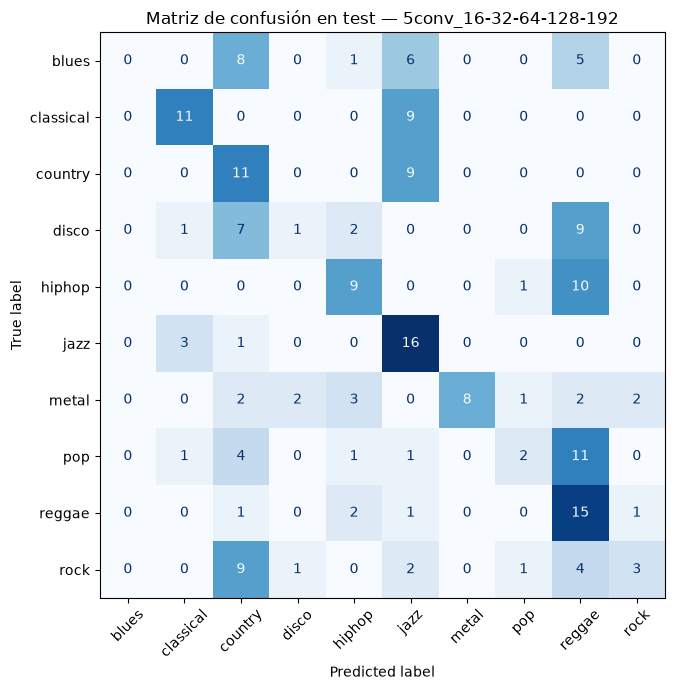

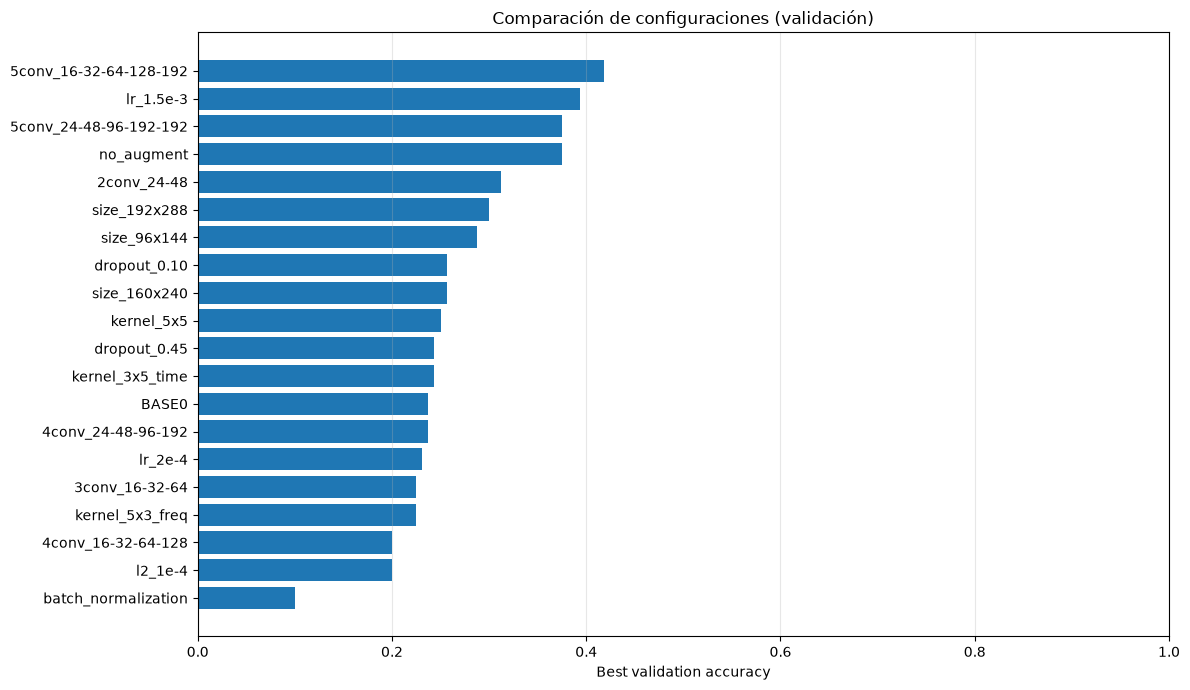

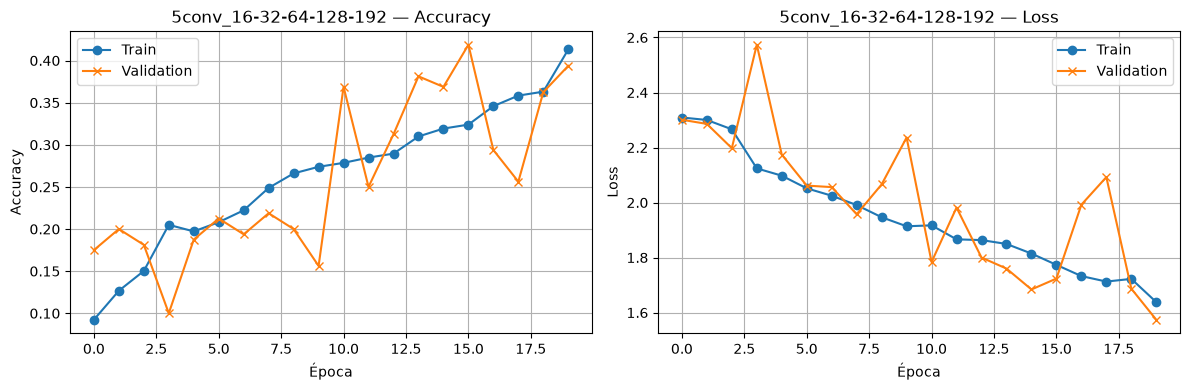

In [21]:
# Tabla ordenada por validation accuracy. No incluye test accuracy por configuración,
# porque el test no debe usarse para comparar ni seleccionar modelos.
sorted_results = sorted(
    experiment_results.items(),
    key=lambda item: item[1]['val_accuracy'],
    reverse=True
)

print(f"{'Configuración':34s} {'Val accuracy':>12s} {'Épocas':>8s}  Parámetros")
print("-" * 120)
for name, run in sorted_results:
    print(
        f"{name:34s} {run['val_accuracy']:12.4f} {run['epochs']:8d}  "
        f"{run['config']}"
    )

# Reconstruir únicamente el mejor modelo y restaurar los pesos guardados.
tf.keras.backend.clear_session()
model = generate_model(num_classes, best_config)
model.set_weights(best_weights)

test_ds = make_dataset(test_paths, test_labels, best_config['size'])
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"\nModelo seleccionado: {best_name}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# Métricas por género y matriz de confusión sobre el test reservado.
y_true = test_labels
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nInforme de clasificación en test:")
print(classification_report(
    y_true, y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False
)
ax.set_title(f'Matriz de confusión en test — {best_name}')
plt.tight_layout()
plt.show()

# Gráfica de validation accuracy para todas las configuraciones.
names = [name for name, _ in sorted_results]
scores = [run['val_accuracy'] for _, run in sorted_results]
plt.figure(figsize=(12, max(5, len(names) * 0.35)))
plt.barh(names[::-1], scores[::-1])
plt.xlabel('Best validation accuracy')
plt.title('Comparación de configuraciones (validación)')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Curvas de entrenamiento de la configuración seleccionada.
selected_history = experiment_results[best_name]['history']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(selected_history['accuracy'], marker='o', label='Train')
axes[0].plot(selected_history['val_accuracy'], marker='x', label='Validation')
axes[0].set(title=f'{best_name} — Accuracy', xlabel='Época', ylabel='Accuracy')
axes[1].plot(selected_history['loss'], marker='o', label='Train')
axes[1].plot(selected_history['val_loss'], marker='x', label='Validation')
axes[1].set(title=f'{best_name} — Loss', xlabel='Época', ylabel='Loss')
for ax in axes:
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 7. Refinamiento
Se mantienen las 4 mejores configuraciones

In [22]:

import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

# ============================================================
# PHASE 2: Fine-tuning the best configurations
# ============================================================

SELECTED_CONFIGS = [
    "5conv_16-32-64-128-192",
    "lr_1.5e-3",
    "5conv_24-48-96-192-192",
    "no_augment"
]

OPT_MAX_EPOCHS = 50
OPT_EARLY_STOPPING_PATIENCE = 8
OPT_LR_PATIENCE = 4
OPT_LR_FACTOR = 0.5
OPT_MIN_LR = 1e-6

optimized_results = {}
optimized_best_weights = None
optimized_best_name = None
optimized_best_accuracy = -1.0
optimized_best_config = None

for idx, name in enumerate(SELECTED_CONFIGS, start=1):

    config = configurations[name].copy()
    original_accuracy = experiment_results[name]["val_accuracy"]

    print(f"\n{'=' * 65}")
    print(f"[{idx}/{len(SELECTED_CONFIGS)}] {name}")
    print(f"Original validation accuracy: {original_accuracy:.4f}")
    print(f"{'=' * 65}")

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    # Keep the original train/validation split
    train_ds = make_dataset(
        train_paths, train_labels,
        config["size"], training=True
    )
    val_ds = make_dataset(
        val_paths, val_labels,
        config["size"], training=False
    )

    candidate = generate_model(num_classes, config)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=OPT_EARLY_STOPPING_PATIENCE,
        restore_best_weights=True
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=OPT_LR_FACTOR,
        patience=OPT_LR_PATIENCE,
        min_lr=OPT_MIN_LR,
        verbose=1
    )

    history = candidate.fit(
        train_ds,
        validation_data=val_ds,
        epochs=OPT_MAX_EPOCHS,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )

    # Metrics at the epoch with the best validation accuracy
    best_epoch_idx = int(np.argmax(history.history["val_accuracy"]))
    new_accuracy = float(
        history.history["val_accuracy"][best_epoch_idx]
    )
    train_accuracy = float(
        history.history["accuracy"][best_epoch_idx]
    )

    optimized_results[name] = {
        "config": config.copy(),
        "original_val_accuracy": float(original_accuracy),
        "val_accuracy": new_accuracy,
        "train_accuracy": train_accuracy,
        "best_epoch": best_epoch_idx + 1,
        "epochs_trained": len(history.history["loss"]),
        "history": {
            key: list(values)
            for key, values in history.history.items()
        }
    }

    if new_accuracy > optimized_best_accuracy:
        optimized_best_accuracy = new_accuracy
        optimized_best_name = name
        optimized_best_config = config.copy()
        optimized_best_weights = [
            w.copy() for w in candidate.get_weights()
        ]

    print(f"\nOriginal val accuracy: {original_accuracy:.4f}")
    print(f"Optimized val accuracy: {new_accuracy:.4f}")
    print(f"Best epoch: {best_epoch_idx + 1}")

    del candidate, history, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# COMPARISON TABLE
# ============================================================

comparison_rows = []

for name, result in optimized_results.items():
    comparison_rows.append({
        "Configuration": name,
        "Original val acc": result["original_val_accuracy"],
        "Optimized val acc": result["val_accuracy"],
        "Improvement": (
            result["val_accuracy"] - result["original_val_accuracy"]
        ),
        "Train acc": result["train_accuracy"],
        "Best epoch": result["best_epoch"],
        "Epochs trained": result["epochs_trained"]
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    "Optimized val acc",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Original val acc": "{:.4f}",
        "Optimized val acc": "{:.4f}",
        "Improvement": "{:+.4f}",
        "Train acc": "{:.4f}"
    })
)

print("\nBest optimized configuration:", optimized_best_name)
print(f"Best optimized validation accuracy: {optimized_best_accuracy:.4f}")
print("Selected parameters:", optimized_best_config)



[1/4] 5conv_16-32-64-128-192
Original validation accuracy: 0.4187
Epoch 1/50


/home/lucialinux/MLSM-labs/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 258ms/step - accuracy: 0.0923 - loss: 2.3092 - val_accuracy: 0.1750 - val_loss: 2.3010 - learning_rate: 5.0000e-04
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.1268 - loss: 2.3002 - val_accuracy: 0.2000 - val_loss: 2.2859 - learning_rate: 5.0000e-04
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.1502 - loss: 2.2663 - val_accuracy: 0.1813 - val_loss: 2.1977 - learning_rate: 5.0000e-04
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.2050 - loss: 2.1242 - val_accuracy: 0.1000 - val_loss: 2.5736 - learning_rate: 5.0000e-04
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 178ms/step - accuracy: 0.1972 - loss: 2.0977 - val_accuracy: 0.1875 - val_loss: 2.1743 - learning_rate: 5.0000e-04
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.2081 - loss: 2.0517 - val_accuracy: 0.2125 - val_loss: 2.0617 - learning_rate: 5.0000e-04
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 187ms/step - accuracy: 0.2222 - lo

AttributeError: The '.style' accessor requires jinja2